# Imports

In [32]:
import os
import shutil
import tensorflow as tf
import random
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input,BatchNormalization

from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from pathlib import Path
from glob import glob
from ultralytics import YOLO
import yaml

import PIL.Image

# Setting up folder structure for data loading

In [5]:
# Defining Paths
images_dir = "images"           # Folder containing IMG_XXXX.jpg
annotations_dir = "annotations" # Folder containing cleaned annotations (only laptops)
base_dir = "dataset"            # Output folder for training/validation split

# Deleting the dataset folder
shutil.rmtree(base_dir, ignore_errors=True)

# Creating the folder structure for training and validation split
def create_folder_structure():
    directories = [
        "Training/Object", "Training/NoObject",
        "Validation/Object", "Validation/NoObject"
    ]
    for directory in directories:
        os.makedirs(os.path.join(base_dir, directory), exist_ok=True)

create_folder_structure()

# Finding out if an image is a laptop
def is_laptop(annotation_file):
    """
    Returns True if a corresponding annotation file exists
    (only laptop images have annotation files in the cleaned annotations folder)
    """
    return os.path.exists(annotation_file)

# Sorting all images into laptop images and non laptop images
laptop_images = []
non_laptop_images = []

# Looping through all the files in images folder instead of annotations
for filename in os.listdir(images_dir):
    if filename.lower().endswith(".jpg"):

        # Getting the name of the image without the file extension
        stem = os.path.splitext(filename)[0]         # IMG_0473

        image_file = os.path.join(images_dir, filename)                 # path to the jpg image
        annotation_file = os.path.join(annotations_dir, stem + ".txt")  # path to the text annotation

        # Sorting images to laptop and non laptop folders
        if is_laptop(annotation_file):
            laptop_images.append(image_file)
        else:
            non_laptop_images.append(image_file)

print("Laptop images:", len(laptop_images))
print("Non laptop images:", len(non_laptop_images))

# Splitting both sets 80/20
def split_80_20(file_list):
    random.shuffle(file_list)
    split_idx = int(len(file_list) * 0.8)
    return file_list[:split_idx], file_list[split_idx:]

train_laptops, val_laptops = split_80_20(laptop_images)
train_non_laptops, val_non_laptops = split_80_20(non_laptop_images)

print("")
print("Training set Laptop images:", len(train_laptops))
print("Validation set Laptop images:", len(val_laptops))
print("Train set NoLaptop images:", len(train_non_laptops))
print("Validation set NoLaptop images:", len(val_non_laptops))
print("")

# Copying files into correct folders
def copy_files(file_list, target_folder):
    for file_path in file_list:
        shutil.copy(file_path, target_folder)

copy_files(train_laptops, os.path.join(base_dir, "Training/Object"))
copy_files(val_laptops, os.path.join(base_dir, "Validation/Object"))
copy_files(train_non_laptops, os.path.join(base_dir, "Training/NoObject"))
copy_files(val_non_laptops, os.path.join(base_dir, "Validation/NoObject"))

# Image generator implementation
train_datagen = ImageDataGenerator(rescale=1./255)
validation_datagen = ImageDataGenerator(rescale=1./255)

# Load and label data from the 'Training' folder
train_generator = train_datagen.flow_from_directory(
    os.path.join(base_dir, "Training"),
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

# Load and label data from the 'Validation' folder
validation_generator = validation_datagen.flow_from_directory(
    os.path.join(base_dir, "Validation"),
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

print("\nTraining Generator Class Indices:", train_generator.class_indices)

Laptop images: 310
Non laptop images: 38

Training set Laptop images: 248
Validation set Laptop images: 62
Train set NoLaptop images: 30
Validation set NoLaptop images: 8

Found 278 images belonging to 2 classes.
Found 70 images belonging to 2 classes.

Training Generator Class Indices: {'NoObject': 0, 'Object': 1}


# Baseline CNN model

In [7]:
model = Sequential([
    Input(shape=(150,150,3)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    
    Flatten(),
    Dense(128, activation='relu'),
    #Dropout(0.5),
    Dense(1, activation='sigmoid')  # binary classification
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

# Training the model

In [9]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10
)

C:\Users\Henna\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 62s 7s/step - accuracy: 0.8921 - loss: 0.5990 - val_accuracy: 0.8857 - val_loss: 0.5251
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 47s 5s/step - accuracy: 0.8921 - loss: 0.3810 - val_accuracy: 0.8857 - val_loss: 0.3460
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 42s 5s/step - accuracy: 0.8921 - loss: 0.3527 - val_accuracy: 0.8857 - val_loss: 0.3479
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 43s 5s/step - accuracy: 0.8921 - loss: 0.2889 - val_accuracy: 0.8857 - val_loss: 0.2749
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 0.8993 - loss: 0.2153 - val_accuracy: 0.9000 - val_loss: 0.2556
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 40s 5s/step - accuracy: 0.9029 - loss: 0.1748 - val_accuracy: 0.8857 - val_loss: 0.2563
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 0.9281 - loss: 0.1330 - val_accuracy: 0.9000 - val_loss: 0.2729
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 42s 5s/step - accuracy: 0.9712 - loss: 0.1146 - val_accuracy: 0.9000 - val_loss: 0.3242
Epoch 9/

# Evaluating the model and saving the weigths

In [11]:
# Evaluating the model on the validation set
val_loss, val_acc = model.evaluate(validation_generator)
print(f"Validation Accuracy: {val_acc:.4f}")

train_loss, train_acc = model.evaluate(train_generator)
print(f"Training Accuracy: {train_acc:.4f}")

# Saving the model
model.save("laptop_classifier.h5")

3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.9000 - loss: 0.3003
Validation Accuracy: 0.9000
9/9 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.9928 - loss: 0.0693


Training Accuracy: 0.9928


# optimizing the CNN model

In [13]:

model = Sequential([
    Input(shape=(150,150,3)),
    
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    
    Flatten(),
    #added L2 regularization and dropout
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.5),
    
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

# Callbacks

In [15]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'best_laptop_classifier.h5',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

In [16]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8614 - loss: 0.8657
Epoch 1: val_loss improved from None to 0.49755, saving model to best_laptop_classifier.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.8777 - loss: 0.6982 - val_accuracy: 0.8857 - val_loss: 0.4976
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8925 - loss: 0.4961
Epoch 2: val_loss improved from 0.49755 to 0.46905, saving model to best_laptop_classifier.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 0.8921 - loss: 0.4897 - val_accuracy: 0.8857 - val_loss: 0.4690
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8537 - loss: 0.5727
Epoch 3: val_loss did not improve from 0.46905
9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 0.8921 - loss: 0.4794 - val_accuracy: 0.8857 - val_loss: 0.4757
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8970 - loss: 0.4328
Epoch 4: val_loss improved from 0.46905 to 0.37385, saving model to best_laptop_classifier.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 0.8921 - loss: 0.4076 - val_accuracy: 0.8857 - val_loss: 0.3739
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9187 - loss: 0.3492
Epoch 5: val_loss improved from 0.37385 to 0.35884, saving model to best_laptop_classifier.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 42s 5s/step - accuracy: 0.9281 - loss: 0.3312 - val_accuracy: 0.9000 - val_loss: 0.3588
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9319 - loss: 0.2604
Epoch 6: val_loss improved from 0.35884 to 0.34226, saving model to best_laptop_classifier.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 42s 5s/step - accuracy: 0.9317 - loss: 0.2625 - val_accuracy: 0.9000 - val_loss: 0.3423
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9504 - loss: 0.2247
Epoch 7: val_loss improved from 0.34226 to 0.34042, saving model to best_laptop_classifier.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 0.9317 - loss: 0.2501 - val_accuracy: 0.9143 - val_loss: 0.3404
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9415 - loss: 0.2463
Epoch 8: val_loss improved from 0.34042 to 0.33170, saving model to best_laptop_classifier.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 0.9424 - loss: 0.2197 - val_accuracy: 0.9143 - val_loss: 0.3317
Epoch 9/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9646 - loss: 0.1847
Epoch 9: val_loss did not improve from 0.33170
9/9 ━━━━━━━━━━━━━━━━━━━━ 42s 5s/step - accuracy: 0.9676 - loss: 0.1871 - val_accuracy: 0.9143 - val_loss: 0.3570
Epoch 10/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9823 - loss: 0.1437
Epoch 10: val_loss did not improve from 0.33170
9/9 ━━━━━━━━━━━━━━━━━━━━ 46s 5s/step - accuracy: 0.9892 - loss: 0.1380 - val_accuracy: 0.9000 - val_loss: 0.3993
Epoch 11/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9822 - loss: 0.1295
Epoch 11: val_loss did not improve from 0.33170
9/9 ━━━━━━━━━━━━━━━━━━━━ 43s 5s/step - accuracy: 0.9784 - loss: 0.1340 - val_accuracy: 0.9000 - val_loss: 0.4068
Epoch 12/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9891 - loss: 0.1271
Epoch 12: val_loss did not improve from 0.33170
9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 5

9/9 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 0.9712 - loss: 0.1875 - val_accuracy: 0.9000 - val_loss: 0.3174
Epoch 14/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9578 - loss: 0.1897
Epoch 14: val_loss did not improve from 0.31739
9/9 ━━━━━━━━━━━━━━━━━━━━ 40s 5s/step - accuracy: 0.9460 - loss: 0.2139 - val_accuracy: 0.9143 - val_loss: 0.3560
Epoch 15/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9826 - loss: 0.1413
Epoch 15: val_loss did not improve from 0.31739
9/9 ━━━━━━━━━━━━━━━━━━━━ 40s 5s/step - accuracy: 0.9748 - loss: 0.1408 - val_accuracy: 0.9143 - val_loss: 0.4462
Epoch 16/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9960 - loss: 0.1442
Epoch 16: val_loss did not improve from 0.31739
9/9 ━━━━━━━━━━━━━━━━━━━━ 42s 5s/step - accuracy: 0.9928 - loss: 0.1415 - val_accuracy: 0.9286 - val_loss: 0.4024
Epoch 17/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9845 - loss: 0.1248
Epoch 17: val_loss did not improve from 0.31739
9/9 ━━━━━━━━━━━━━━━━━━━━ 42s

In [17]:
val_loss, val_acc = model.evaluate(validation_generator)

print(f"Validation Accuracy: {val_acc:.4f}")

train_loss, train_acc = model.evaluate(train_generator)
print(f"Training Accuracy: {train_acc:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.9000 - loss: 0.3174
Validation Accuracy: 0.9000
9/9 ━━━━━━━━━━━━━━━━━━━━ 32s 3s/step - accuracy: 0.9748 - loss: 0.1476
Training Accuracy: 0.9748


# saving final model

In [19]:
# Save final model
model.save("laptop_classifier_final.h5")

# classification metrics

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
import numpy as np

# get labels
y_true = validation_generator.classes

# get predictions
pred_probs = model.predict(validation_generator)
pred_labels = (pred_probs > 0.5).astype(int).reshape(-1)

# compute metrics
accuracy = accuracy_score(y_true, pred_labels)
precision = precision_score(y_true, pred_labels)
recall = recall_score(y_true, pred_labels)

accuracy, precision, recall

3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step


(0.8428571428571429, 0.8923076923076924, 0.9354838709677419)

Transfer learning for object detection part of the project

In [23]:
# Just a heads up, this takes a long long while to run with just CPU
yolo_base = "yolo_dataset"
shutil.rmtree(yolo_base, ignore_errors=True)

os.makedirs(f"{yolo_base}/train/images", exist_ok=True)
os.makedirs(f"{yolo_base}/train/labels", exist_ok=True)
os.makedirs(f"{yolo_base}/val/images", exist_ok=True)
os.makedirs(f"{yolo_base}/val/labels", exist_ok=True)


def copy_yolo_pairs(image_paths, split):
    for image_path in image_paths:
        stem = os.path.splitext(os.path.basename(image_path))[0]
        label_path = os.path.join(annotations_dir, stem + ".txt")

        # copies the images
        shutil.copy(image_path, f"{yolo_base}/{split}/images")

        # also  copies the annotations
        if os.path.exists(label_path):
            shutil.copy(label_path, f"{yolo_base}/{split}/labels")
        else:
            # adds empty label files for photos without annotations (no object in pic)
            open(f"{yolo_base}/{split}/labels/{stem}.txt", "w").close()

# fills the dataset
copy_yolo_pairs(train_laptops + train_non_laptops, "train")
copy_yolo_pairs(val_laptops + val_non_laptops, "val")

print("YOLO dataset created.")


# creates yaml file needed for yolo
data_yaml = {
    "path": yolo_base,
    "train": "train/images",
    "val": "val/images",
    "names": {0: "laptop"}
}

with open("yolo_data.yaml", "w") as f:
    yaml.dump(data_yaml, f)

print("yolo_data.yaml saved.")


# loads pretrained model, v5 in this case
yolo_model = YOLO("yolov5s.pt")

# Training
results = yolo_model.train(
    data="yolo_data.yaml",
    epochs=20,
    imgsz=640,
    batch=8,
    name="laptop_yolo_model",
    project="."
)

print("YOLO training complete.")



test_output_dir = "yolo_predictions"
os.makedirs(test_output_dir, exist_ok=True)

val_images = glob(f"{yolo_base}/val/images/*.jpg")

# inference
for img_path in val_images:
    yolo_model.predict(source=img_path, save=True, project=test_output_dir, exist_ok=True)

print("YOLO predictions saved to:", test_output_dir)

YOLO dataset created.
yolo_data.yaml saved.
PRO TIP  Replace 'model=yolov5s.pt' with new 'model=yolov5su.pt'.
YOLOv5 'u' models are trained with https://github.com/ultralytics/ultralytics and feature improved performance vs standard YOLOv5 models trained with https://github.com/ultralytics/yolov5.

New https://pypi.org/project/ultralytics/8.3.234 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.233  Python-3.11.7 torch-2.9.1+cpu CPU (Intel Core i7-7700HQ 2.80GHz)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=yolo_data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=Fals

### Style Transform - Final Part

In [25]:
#Pictures and YOLO model from previous part

val_images = glob(f"yolo_dataset/val/images/*.jpg")
yolo_model = YOLO("laptop_yolo_model/weights/best.pt")

In [34]:
#Convert [0,1] float → [0,255] image pixels

def tensor_to_image(tensor):
  tensor = tensor*255
  tensor = np.array(tensor, dtype=np.uint8)
  if np.ndim(tensor)>3:
    assert tensor.shape[0] == 1
    tensor = tensor[0]
  return PIL.Image.fromarray(tensor) #converts the NumPy array into a PIL Image object (convert to displayable image)

In [36]:
#Load style image from Keras website
#This downloads Kandinsky’s painting, loads it, resizes it, normalizes it, and returns a ready-to-use tensor

def load_img(path_to_img):

  max_dim = 512 # maximum size for the image’s longest side
  img = tf.io.read_file(path_to_img)
  img = tf.image.decode_image(img, channels=3) #channel=3 makes sure it becomes RGB
  img = tf.image.convert_image_dtype(img, tf.float32) #convert [0, 255] → floats in [0.0, 1.0]

  shape = tf.cast(tf.shape(img)[:-1], tf.float32) #[:-1] removes channels, just [height, width]
  long_dim = max(shape)
  scale = max_dim / long_dim # example: 512 / 1920 ≈ 0.266

  new_shape = tf.cast(shape * scale, tf.int32) # multiplies both dimensions by the same scale, example [1080, 1920] * 0.266 → [287, 512]

  img = tf.image.resize(img, new_shape)
  img = img[tf.newaxis, :]
  return img

#downloads Kandinsky’s painting
style_path = tf.keras.utils.get_file('kandinsky5.jpg','https://storage.googleapis.com/download.tensorflow.org/example_images/Vassily_Kandinsky%2C_1913_-_Composition_7.jpg')

style_image = load_img(style_path)


In [38]:
import tensorflow_hub as hub

#Loading a image stylization

hub_model = hub.load('https://tfhub.dev/google/magenta/arbitrary-image-stylization-v1-256/2')

In [40]:
#Convert img to suitable format for stylization model

def style_transform(img):
    
    max_dim = 512
    
    img = tf.image.convert_image_dtype(img, tf.float32)
    shape = tf.cast(tf.shape(img)[:-1], tf.float32)
    long_dim = max(shape)
    scale = max_dim / long_dim
    new_shape = tf.cast(shape * scale, tf.int32)

    img = tf.image.resize(img, new_shape)
    img = img[tf.newaxis, :]

    #Stylize the image
    stylized_image = hub_model(tf.constant(img), tf.constant(style_image))[0] #Stylization of the image
    
    stylized_image = tf.image.resize(stylized_image, tf.cast(shape, tf.int32)) #Resize stylized image back to original size
    res = tensor_to_image(stylized_image)

    return res


image 1/1 C:\Users\Henna\Downloads\deep-learning\yolo_dataset\val\images\IMG-20251125-WA0002.jpg: 480x640 1 laptop, 132.3ms
Speed: 2.4ms preprocess, 132.3ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)


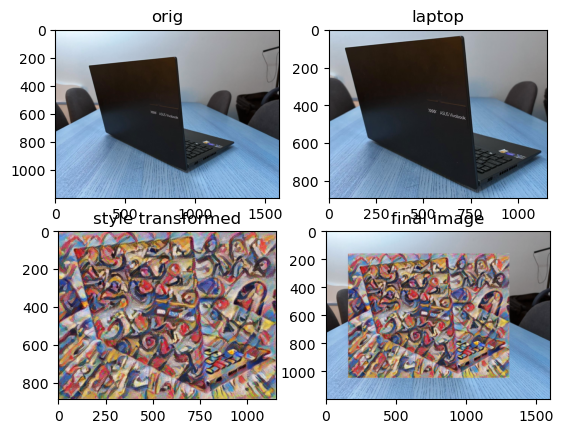

Saving to  final_images/IMG-20251125-WA0002.jpg

image 1/1 C:\Users\Henna\Downloads\deep-learning\yolo_dataset\val\images\IMG-20251125-WA0010.jpg: 480x640 2 laptops, 148.7ms
Speed: 2.7ms preprocess, 148.7ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)


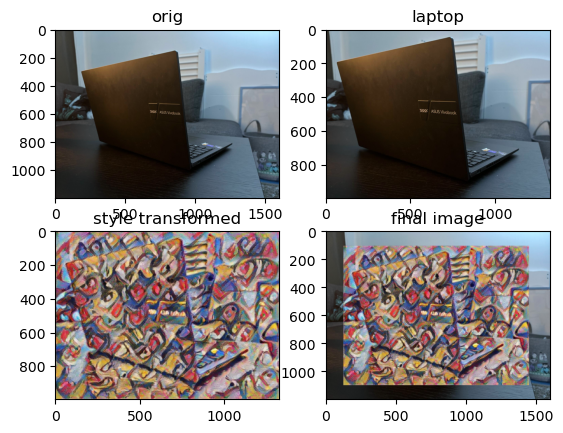

Saving to  final_images/IMG-20251125-WA0010.jpg

image 1/1 C:\Users\Henna\Downloads\deep-learning\yolo_dataset\val\images\IMG-20251125-WA0011.jpg: 480x640 1 laptop, 164.4ms
Speed: 2.7ms preprocess, 164.4ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 640)


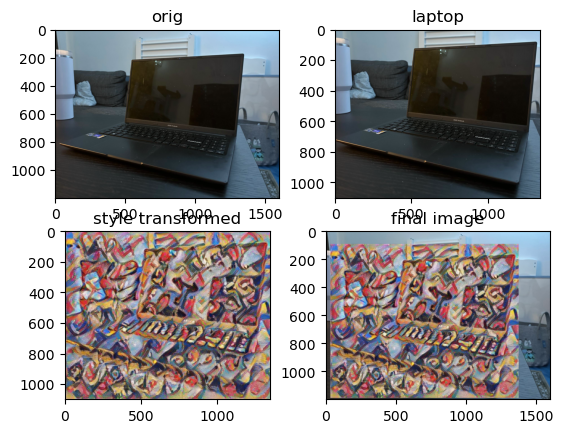

Saving to  final_images/IMG-20251125-WA0011.jpg

image 1/1 C:\Users\Henna\Downloads\deep-learning\yolo_dataset\val\images\IMG-20251125-WA0013.jpg: 480x640 1 laptop, 162.3ms
Speed: 3.8ms preprocess, 162.3ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)


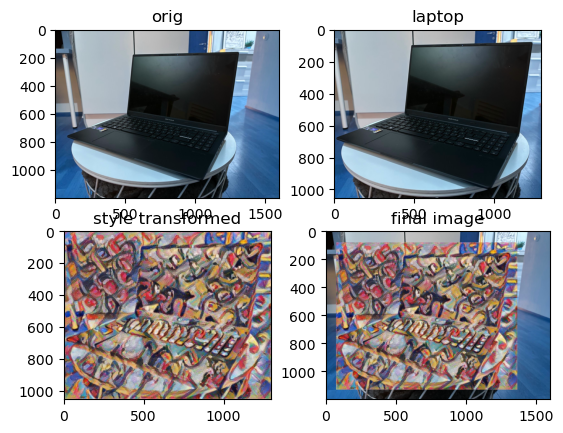

Saving to  final_images/IMG-20251125-WA0013.jpg


In [50]:
import cv2 as cv
from matplotlib import pyplot as plt
%matplotlib inline

# create directory for saving final images
output_dir = "final_images"
os.makedirs(output_dir, exist_ok=True)

counter = 0
#takes one image at the time and predict laptop locations
for img_path in val_images:

    result2 = yolo_model.predict(source=img_path)
    orig_img = result2[0].orig_img
    box=result2[0].boxes.xyxy

    #skip images without laptop
    if len(box) == 0:
        continue
    
    #coordinates of the bounding box
    x1 = int(box[0][0])
    y1 = int(box[0][1])
    x2 = int(box[0][2])
    y2 = int(box[0][3])


    plt.subplot(221) #original image
    plt.imshow(orig_img)
    plt.title('orig')

    laptop = orig_img[y1:y2,x1:x2]
    
    plt.subplot(222) # image from annotation
    plt.imshow(laptop)
    plt.title('laptop')
    
    #laptop modified with style transform function
    style_result = style_transform(laptop)
    
    plt.subplot(223) 
    plt.imshow(style_result)
    plt.title('style transformed')

    #paste modified image to the original
    final_img = orig_img.copy()
    final_img[y1:y2, x1:x2] = style_result
    
    plt.subplot(224)
    plt.imshow(final_img)
    plt.title('final image')
    
    plt.show()

    #create final image file path
    img_name = os.path.basename(img_path)
    final_path = output_dir + '/' + img_name
    print("Saving to ", final_path)
    cv.imwrite(final_path, final_img) #saves final images to the file

    if counter == 3:
        break
    counter += 1
